In [1]:
import control as ctrl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

In [2]:
# Transfer Functions

# 6/(s+1)(s+2)(s+3)
G1 = ctrl.TransferFunction([6], [1, 6, 11, 6])

# 2(s+2)/s^3 - 3s^2 + 2s + 4
G2 = ctrl.TransferFunction([2, 4], [1, -3, 2, 4])

# 1/s^4 + 5s^3 + 2s^2 - 7s + 1
G3 = ctrl.TransferFunction([1], [1, 5, 2, -7, 1])

# 12(s+2)/(s-1)(s-2)(s+3)(s+4)
G4 = ctrl.TransferFunction([12, 24], [1, 4, -7, -22, 24])

# 120/(s+1)(s+2)(s+3)(s+4)(s+5)
G5 = ctrl.TransferFunction(
    [120],
    [1, 15, 85, 225, 274, 120]
)

# 720/(s+1)(s+2)(s+3)(s+4)(s+5)(s+6)
G6 = ctrl.TransferFunction(
    [720],
    [1, 21, 175, 735, 1624, 1764, 720]
)

# Fix Kd
Kd = 0.5
systems = {
    "-6/(s+1)(s-2)(s+3)": G1,
    "2(s+2)/s^3 - 3s^2 + 2s + 4": G2,
    "1/s^4 + 5s^3 + 2s^2 - 7s + 1": G3,
    "12(s+2)/(s-1)(s-2)(s+3)(s+4)": G4,
    "120/(s+1)(s+2)(s+3)(s+4)(s+5)": G5,
    "720/(s+1)(s+2)(s+3)(s+4)(s+5)(s+6)": G6
}


In [3]:
# PID controller: Kd*s^2 + Kp*s + Ki, divided by s

import numpy as np
import control as ctrl

def is_stable(Kp, Ki, Kd, plant, eps=0.01):
    controller = ctrl.TransferFunction(
        [Kd, Kp, Ki], [1, 0]
    )

    closed_loop = ctrl.feedback(controller * plant, 1)

    # Simulate the closed-loop unit-step response
    t = np.linspace(0, 300, 300)

    try:
        response = ctrl.step_response(closed_loop, T=t)
        y = np.asarray(response.outputs).squeeze()

        if not np.all(np.isfinite(y)):
            return False

        # Reject responses that grow excessively
        if np.max(np.abs(y)) > 10:
            return False

        final_value = y[-1]

        # Overshoot relative to the final value
        if abs(final_value) < 1e-8:
            overshoot = np.inf
        else:
            overshoot = max(
                0.0,
                (np.max(y) - final_value) / abs(final_value) * 100
            )

        # Settling criterion: output remains within 1% of final value
        tolerance = max(eps * abs(final_value), eps)
        outside = np.where(np.abs(y - final_value) > tolerance)[0]

        if len(outside) == 0:
            settling_time = 0.0
        elif outside[-1] == len(t) - 1:
            settling_time = np.inf
        else:
            settling_time = t[outside[-1] + 1]

        return (overshoot < 10) and (settling_time < 300)

    except (ValueError, RuntimeError, TypeError, np.linalg.LinAlgError):
        return False

        



Processing -6/(s+1)(s-2)(s+3)...


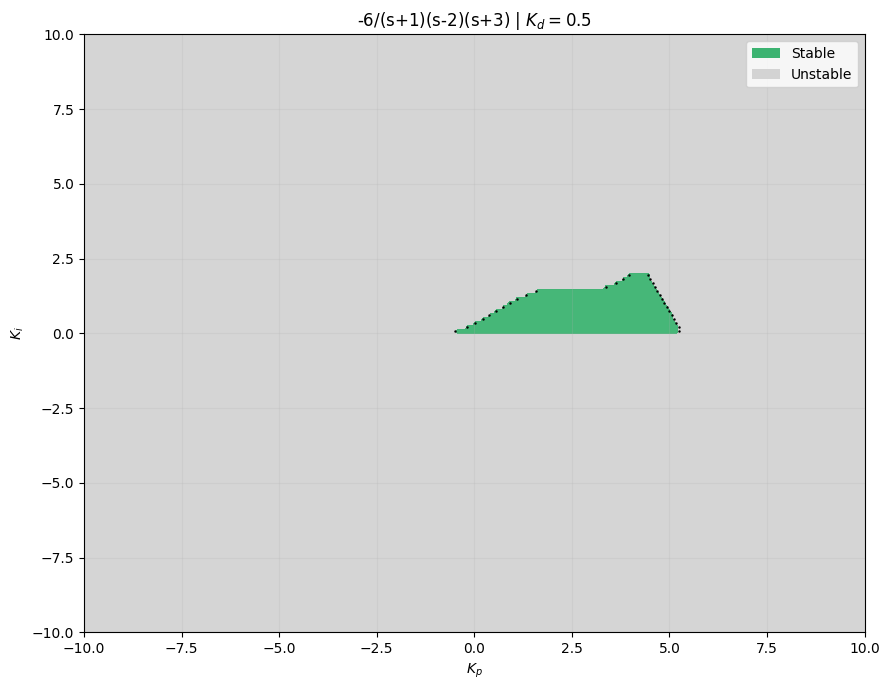

Ki rows scanned: 150
Refined boundary transitions: 30

Processing 2(s+2)/s^3 - 3s^2 + 2s + 4...


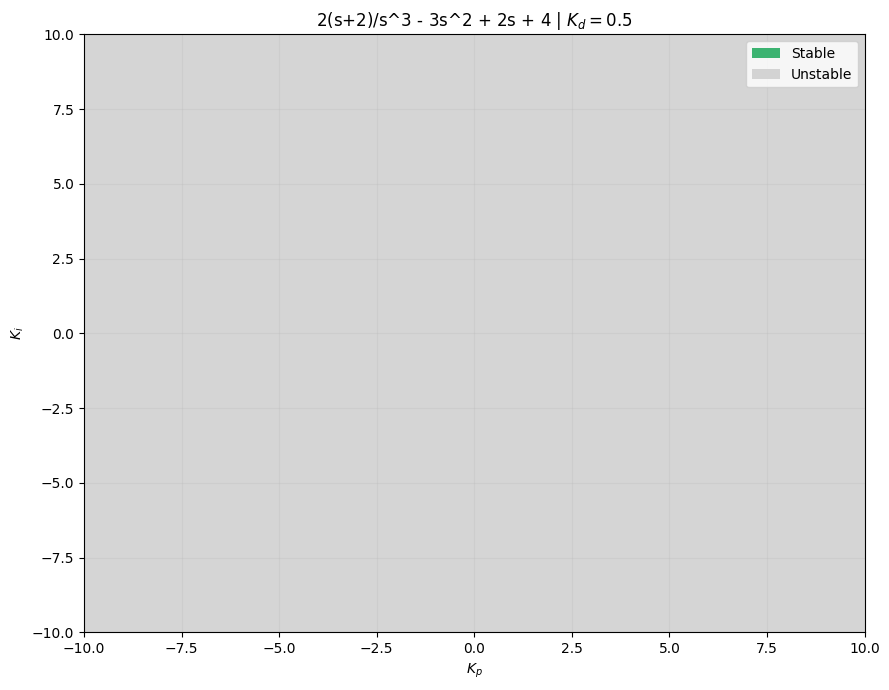

Ki rows scanned: 150
Refined boundary transitions: 0

Processing 1/s^4 + 5s^3 + 2s^2 - 7s + 1...


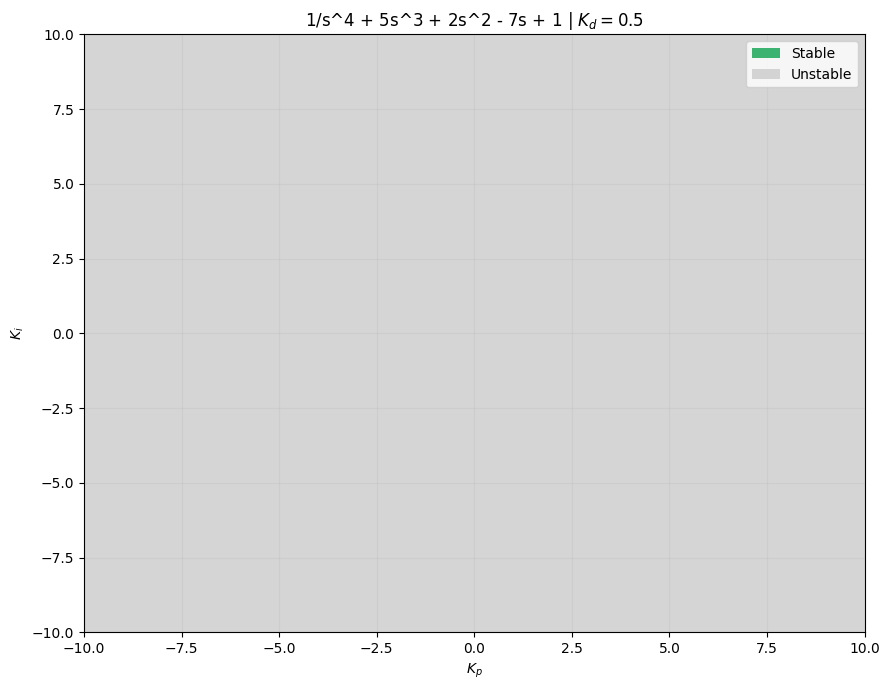

Ki rows scanned: 150
Refined boundary transitions: 0

Processing 12(s+2)/(s-1)(s-2)(s+3)(s+4)...


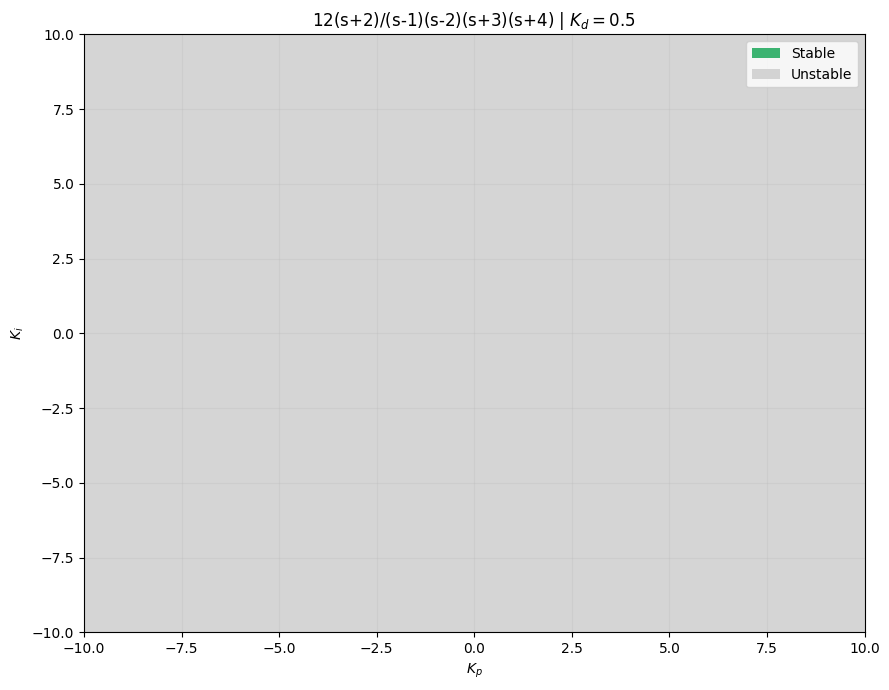

Ki rows scanned: 150
Refined boundary transitions: 0

Processing 120/(s+1)(s+2)(s+3)(s+4)(s+5)...


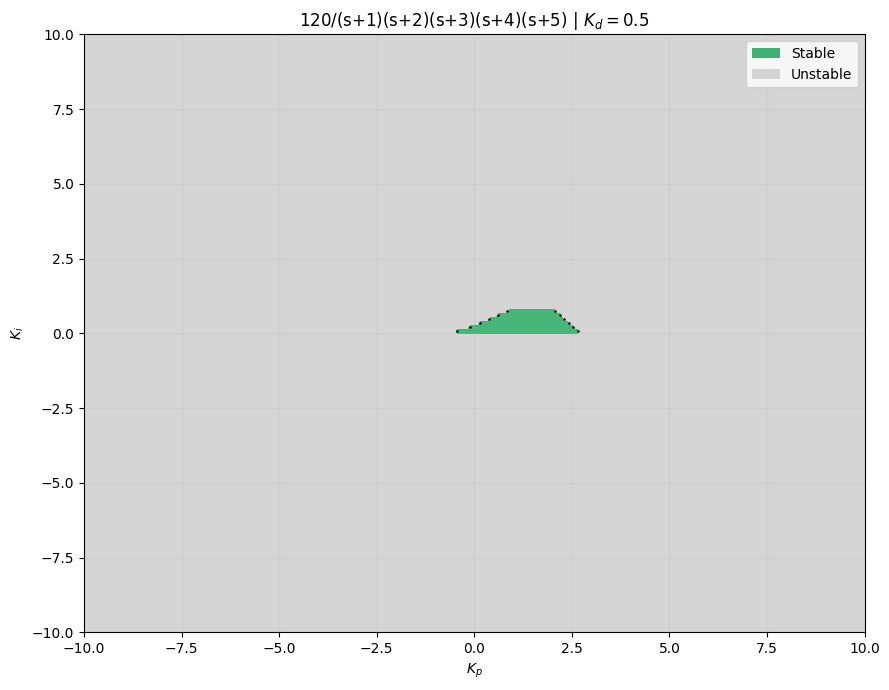

Ki rows scanned: 150
Refined boundary transitions: 12

Processing 720/(s+1)(s+2)(s+3)(s+4)(s+5)(s+6)...


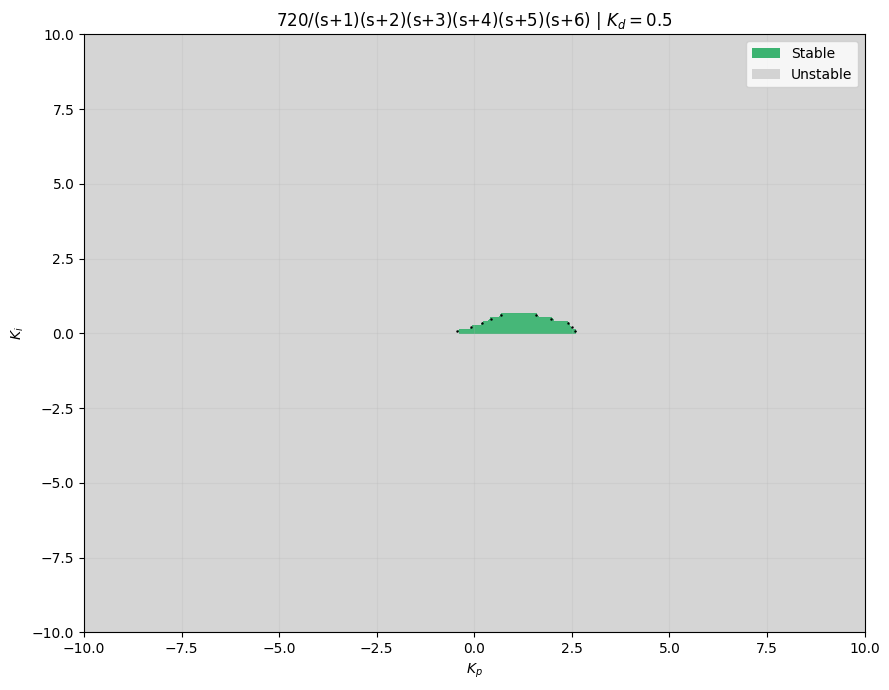

Ki rows scanned: 150
Refined boundary transitions: 10


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


def trace_row_boundaries(
    Ki, plant, Kd,
    kp_min=0, kp_max=10,
    coarse_steps=30,
    binary_iterations=20
):
    """
    For a fixed Ki:
      1. Coarsely scan Kp.
      2. Detect every transition between adjacent samples.
      3. Refine each detected transition using binary search.

    Returns:
        initial_stable: stability at kp_min
        boundaries: refined Kp values of transitions
    """

    kp_samples = np.linspace(kp_min, kp_max, coarse_steps + 1)

    stable_samples = [
        bool(is_stable(kp, Ki, Kd, plant))
        for kp in kp_samples
    ]

    initial_stable = stable_samples[0]
    boundaries = []

    # Refine every transition found by the coarse scan
    for i in range(coarse_steps):
        if stable_samples[i] == stable_samples[i + 1]:
            continue

        low = kp_samples[i]
        high = kp_samples[i + 1]
        left_stable = stable_samples[i]

        for _ in range(binary_iterations):
            mid = (low + high) / 2
            mid_stable = bool(is_stable(mid, Ki, Kd, plant))

            if mid_stable == left_stable:
                low = mid
            else:
                high = mid

        boundaries.append((low + high) / 2)

    return initial_stable, boundaries


def plot_stability_region(
    plant, system_name, Kd=0.5,
    kp_min=0, kp_max=10,
    ki_min=0, ki_max=10,
    ki_steps=120,
    coarse_kp_steps=30,
    plot_kp_steps=300,
    binary_iterations=20
):
    """
    Scan Kp coarsely for each Ki, refine boundaries,
    then fill the stability map for visualization.
    """

    ki_values = np.linspace(ki_min, ki_max, ki_steps)
    kp_plot = np.linspace(kp_min, kp_max, plot_kp_steps)

    # Rows correspond to Ki; columns correspond to Kp
    stability_map = np.zeros(
        (ki_steps, plot_kp_steps), dtype=int
    )

    all_boundaries = []

    for row, Ki in enumerate(ki_values):
        initial_stable, boundaries = trace_row_boundaries(
            Ki=Ki,
            plant=plant,
            Kd=Kd,
            kp_min=kp_min,
            kp_max=kp_max,
            coarse_steps=coarse_kp_steps,
            binary_iterations=binary_iterations
        )

        all_boundaries.append(boundaries)

        # Classify the plotting grid using the refined transitions.
        # Stability toggles at each detected transition.
        stable = initial_stable
        boundary_index = 0

        for col, Kp in enumerate(kp_plot):
            while (
                boundary_index < len(boundaries)
                and Kp >= boundaries[boundary_index]
            ):
                stable = not stable
                boundary_index += 1

            stability_map[row, col] = int(stable)

    KP, KI = np.meshgrid(kp_plot, ki_values)

    # Filled stability map
    fig, ax = plt.subplots(figsize=(9, 7))

    ax.contourf(
        KP, KI, stability_map,
        levels=[-0.5, 0.5, 1.5],
        colors=["lightgrey", "mediumseagreen"],
        alpha=0.95
    )

    # Plot refined boundary points and connect them approximately
    for i in range(len(ki_values)):
        for boundary in all_boundaries[i]:
            ax.plot(
                boundary, ki_values[i],
                marker=".",
                color="black",
                markersize=1.5
            )

    # Add legend
    ax.legend(handles=[
        Patch(facecolor="mediumseagreen", label="Stable"),
        Patch(facecolor="lightgrey", label="Unstable"),
    ], loc="upper right")

    ax.set_xlabel(r"$K_p$")
    ax.set_ylabel(r"$K_i$")
    ax.set_title(f"{system_name} | $K_d={Kd}$")
    ax.set_xlim(kp_min, kp_max)
    ax.set_ylim(ki_min, ki_max)
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    total_boundaries = sum(len(b) for b in all_boundaries)
    print(f"Ki rows scanned: {ki_steps}")
    print(f"Refined boundary transitions: {total_boundaries}")

    return KP, KI, stability_map, all_boundaries


# Run for every transfer function in your systems dictionary
for system_name, plant in systems.items():
    print(f"\nProcessing {system_name}...")

    KP, KI, stability_map, boundaries = plot_stability_region(
        plant=plant,
        system_name=system_name,
        Kd=Kd,
        kp_min=-10,
        kp_max=10,
        ki_min=-10,
        ki_max=10,
        ki_steps=150,
        coarse_kp_steps=40,
        plot_kp_steps=300,
        binary_iterations=30
    )